In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib
import matplotlib.pyplot as plt
import os, json
import gpflow
import tensorflow as tf

import warnings
warnings.filterwarnings("ignore")

import sys
from utils.pyfunctions import *
from utils.hm_pyfunctions import *

2026-11-25 09:24:58.767767: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-25 09:24:58.790271: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1795623898.810816   39912 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1795623898.817921   39912 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-25 09:24:58.840181: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
# get config information
utils_dir = '../utils/'

with open(os.path.join(utils_dir, "param_info.json"), "r") as f:
    param_info = json.load(f)
u_params = param_info['u_params']
pft_params = param_info['pft_params']

with open(os.path.join(utils_dir, "biome_info.json"), "r") as f:
    biome_info = json.load(f)

# load observational data
obs = xr.open_dataset('../data/obs_statistics_byBiome.nc')

### Load data

In [3]:
### Load data
ds_params_lhc = xr.open_dataset('../clm-hm/paramsets/clm6lhc_01192025_v3.nc')
ds_lhc = xr.open_dataset('../data/ctsm53065_lhc_biome_1850-2023.nc')

### Load wave1 data
ds_params_wave1 = xr.open_dataset('../clm-hm/paramsets/ctsm53065_wave1_12032025.nc')
ds_wave1 = xr.open_dataset('../data/ctsm53065_wave1_biome_1850-2023.nc')

### Load wave2 data
ds_params_wave2 = xr.open_dataset('../clm-hm/paramsets/ctsm53065_wave2_12232025.nc')
ds_wave2 = xr.open_dataset('../data/ctsm53065_wave2_biome_1850-2023.nc')

### Load wave3 data
ds_params_wave3 = xr.open_dataset('../clm-hm/paramsets/ctsm53065_wave3_01012026.nc')
ds_wave3 = xr.open_dataset('../data/ctsm53065_wave3_biome_1850-2023.nc')

### Load wave4 data
ds_params_wave4 = xr.open_dataset('../clm-hm/paramsets/ctsm53065_wave4_02042026.nc')
ds_wave4 = xr.open_dataset('../data/ctsm53065_wave4_biome_1850-2023.nc')

### Load HMC data
ds_params_hmc = xr.open_dataset('../clm-hmc/paramsets/ctsm53065_hmc_05042026.nc')
ds_hmc = xr.open_dataset('../data/ctsm53065_hmc_biome_1850-2023.nc')


In [4]:
# concat
ds_X = xr.concat([ds_params_lhc.lhc_params, ds_params_wave1.wave1_params, ds_params_wave2.wave2_params, 
                  ds_params_wave3.wave3_params, ds_params_wave4.wave4_params, ds_params_hmc.hmc_params], dim="ens")
ds_X = ds_X.assign_coords(ens=range(0, len(ds_X.ens)))
ds_Y = xr.concat([ds_lhc.sel(ens=slice(1,201)),ds_wave1,ds_wave2,ds_wave3,ds_wave4,ds_hmc],dim='ens') # drop default lhc0000

In [6]:
# train test split (same for all emulators)
np.random.seed(20)
ntest = 200
biome_pfts = biome_info['13']['pfts_in_biome']
X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
ix_test = np.random.choice(np.arange(len(X)), size=ntest, replace=False)
ix_train = np.where(~np.isin(np.arange(len(X)), ix_test))[0]

In [7]:
ix_test = np.arange(801,999)

In [8]:
paths = ['../clm-hm/wave1_emulators/',
         '../clm-hm/wave2_emulators/',
         '../clm-hm/wave3_emulators/',
         '../clm-hm/wave4_emulators/',
         '../clm6-hmc/emulators/'
        ]

In [10]:
# LAI
r2_lai_eval = np.empty((4,13))
var_lai_eval= np.empty((4,13))

start_year = '2001'
end_year = '2020'
y_data = ds_Y.TLAI_biome_amax.sel(year=slice(start_year,end_year)).mean(dim='year')

for w in range(1,5):
    emulator_dir = paths[w-1]+'biome_lai_'
    for b in range(1,14):
        biome_pfts = biome_info[str(b)]['pfts_in_biome']
        X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
        Y = y_data.sel(biome=b).values
        X_test = X[ix_test,:]
        y_test = Y[ix_test]#.reshape(-1,1)
    
        loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
        y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
        r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
        r2_lai_eval[w-1,b-1] = round(r2[0,1],3)
        var_lai_eval[w-1,b-1]= np.median(y_pred_var)


2026-11-25 09:25:28.379329: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


In [11]:
# GPP
r2_gpp_eval = np.empty((4,13))
var_gpp_eval= np.empty((4,13))

start_year = '2001'
end_year = '2017'
y_data = ds_Y.GPP_biome_amean.sel(year=slice(start_year,end_year)).mean(dim='year')

for w in range(1,5):
    emulator_dir = paths[w-1]+'biome_gpp_'
    for b in range(1,14):
        biome_pfts = biome_info[str(b)]['pfts_in_biome']
        X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
        Y = y_data.sel(biome=b).values
        X_test = X[ix_test,:]
        y_test = Y[ix_test]#.reshape(-1,1)
    
        loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
        y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
        r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
        r2_gpp_eval[w-1,b-1] = round(r2[0,1],3)
        var_gpp_eval[w-1,b-1]= np.median(y_pred_var)

In [12]:
# TVC
r2_tvc_eval = np.empty((4,13))
var_tvc_eval = np.empty((4,13))

start_year = '2000'
end_year = '2019'
y_data = ds_Y.TOTVEGC_biome_amean.sel(year=slice(start_year,end_year)).mean(dim='year')

for w in range(1,5):
    emulator_dir = paths[w-1]+'biome_tvc_'
    for b in range(1,14):
        biome_pfts = biome_info[str(b)]['pfts_in_biome']
        X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
        Y = y_data.sel(biome=b).values
        X_test = X[ix_test,:]
        y_test = Y[ix_test]#.reshape(-1,1)
    
        loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
        y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
        r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
        r2_tvc_eval[w-1,b-1] = round(r2[0,1],3)
        var_tvc_eval[w-1,b-1] = np.mean(y_pred_var)

In [13]:
# Latent Heat
r2_lh_eval = np.empty((4,13))
var_lh_eval = np.empty((4,13))

start_year = '2000'
end_year = '2014'
y_data = ds_Y.EFLX_LH_TOT_biome_amean.sel(year=slice(start_year,end_year)).mean(dim='year')

for w in range(1,5):
    emulator_dir = paths[w-1]+'biome_lh_'
    for b in range(1,14):
        biome_pfts = biome_info[str(b)]['pfts_in_biome']
        X = build_biome_X(ds_X,u_params,pft_params,biome_pfts)
        Y = y_data.sel(biome=b).values
        X_test = X[ix_test,:]
        y_test = Y[ix_test]#.reshape(-1,1)
    
        loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
        y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
        r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
        r2_lh_eval[w-1,b-1] = round(r2[0,1],3)
        var_lh_eval[w-1,b-1] = np.median(y_pred_var)


In [14]:
from matplotlib.colors import ListedColormap, BoundaryNorm

N = 13

biome_colors = [
    "#004D19","#5D9945","darkseagreen",  # (tropic, tropic, savanna,)
    "#DECAA7", "#D2B48C", # (grasslands, shrublands)
    "#859457","#A1AF78","lightblue","cadetblue","teal",# (mixed decid, conifer, larch)
    "thistle","lavenderblush","lavender", # (boreal forest, aspen, boreal shrub, tundra)
    "grey",
]


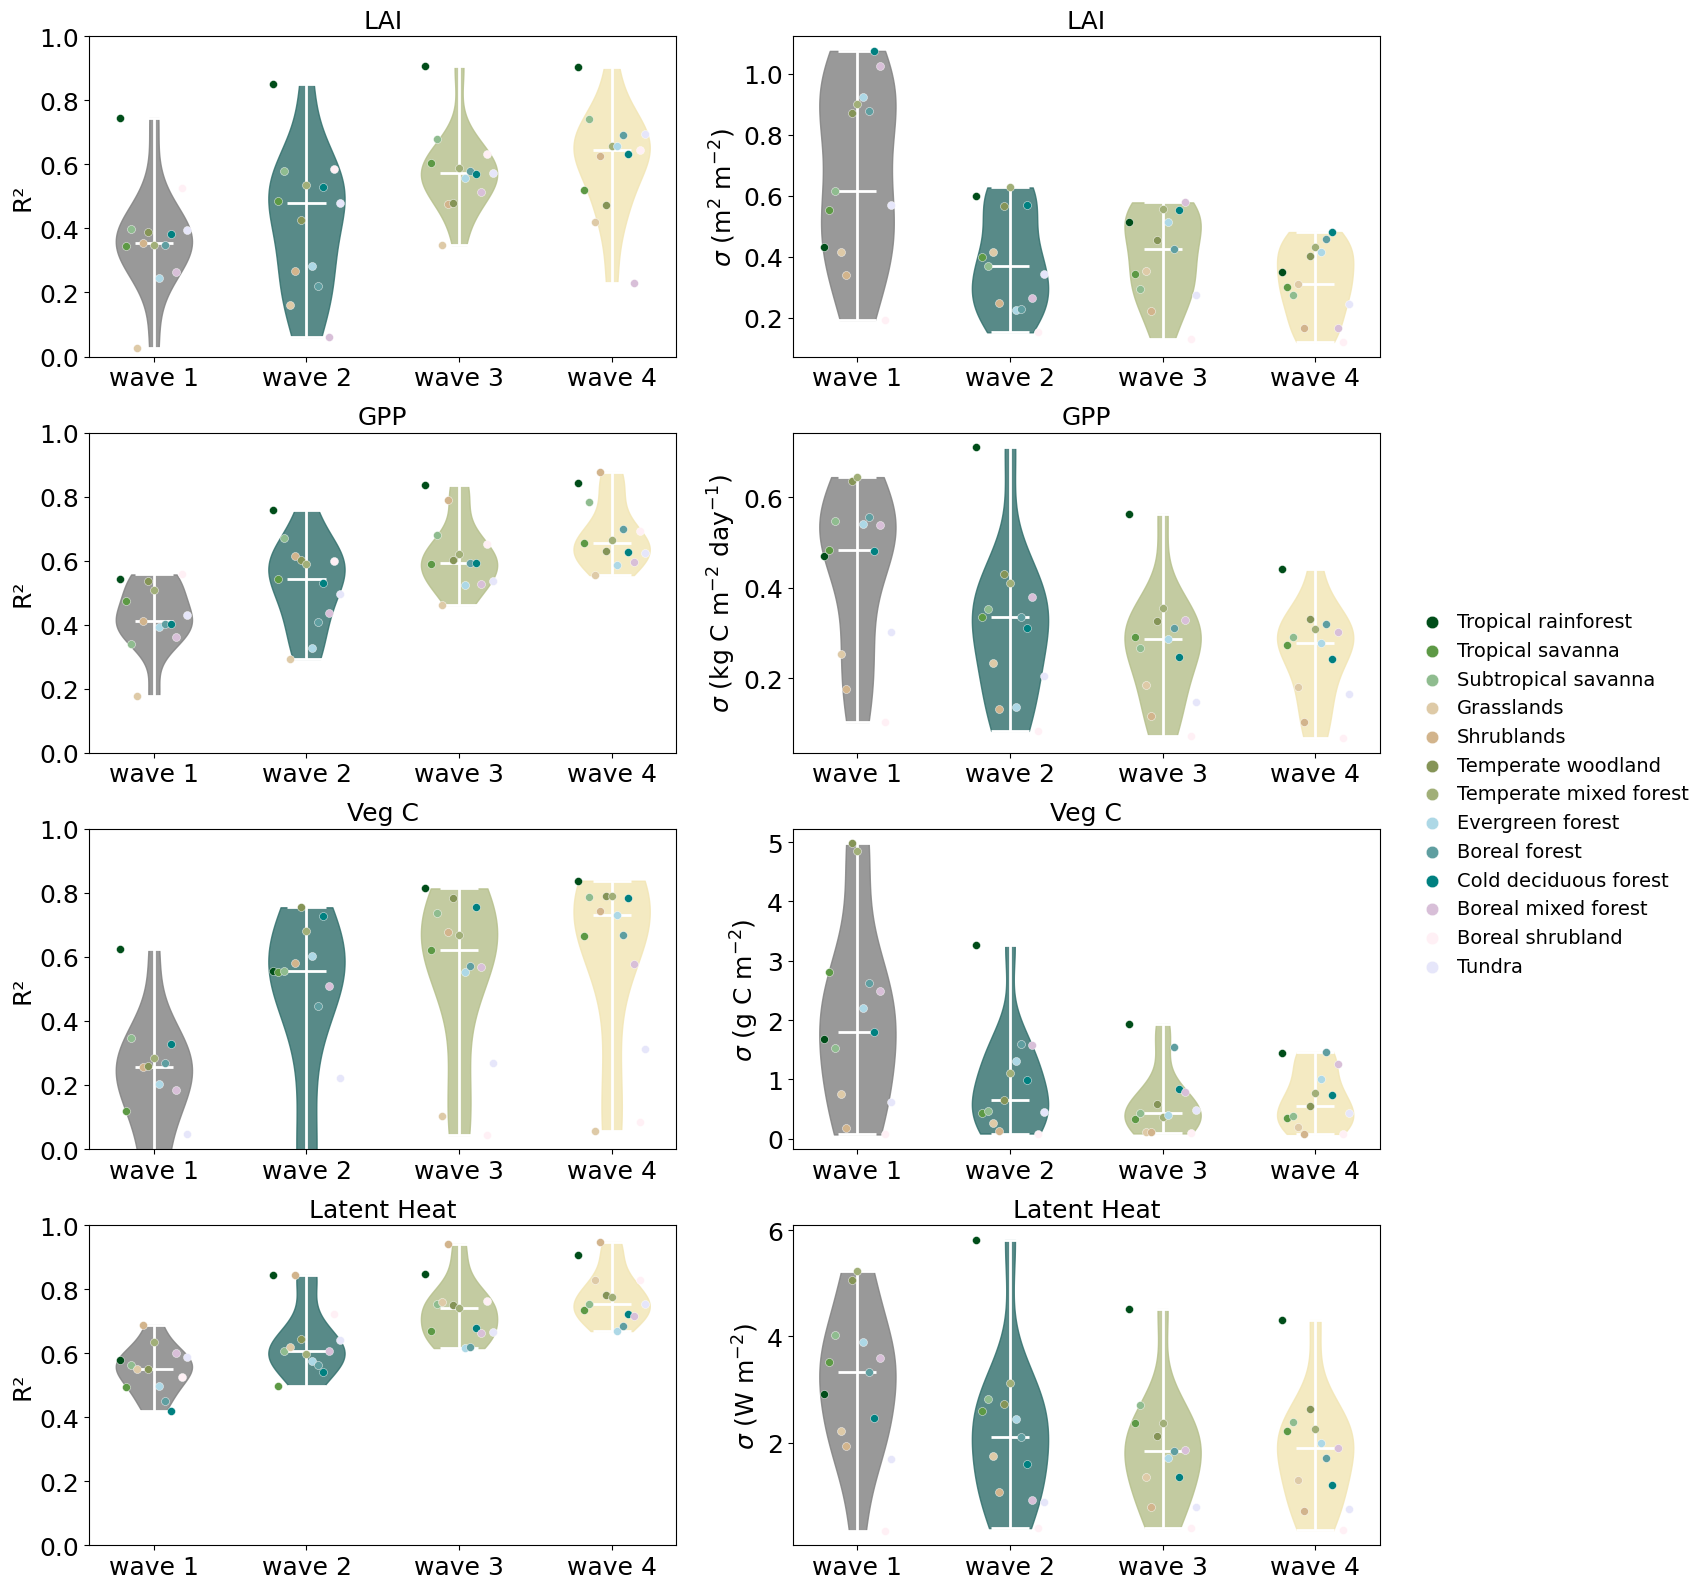

In [15]:
# Create multi-panel figure with all emulator evaluations
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
biome_names = [biome_info[str(num)]['name'] for num in range(1, 14)]
# Colors for violins
colors = ['grey','#2E6D6A', '#B5BF8A','#F2E5B3', '#E4AD6A','#025196','k']

# Helper function to create violin plots
def plot_violin(ax, data, ylabel, title, show_ylim_one=True):
    parts = ax.violinplot(data.T, showmeans=False, showmedians=True)
    
    for i, vp in enumerate(parts['bodies']):
        vp.set_facecolor(colors[i])
        vp.set_edgecolor(colors[i])
        vp.set_alpha(0.8)
    
    for partname, element in parts.items():
        if partname == 'bodies':
            continue
        if hasattr(element, 'set_color'):
            element.set_color('white')
        if hasattr(element, 'set_facecolor'):
            element.set_facecolor('white')
        if hasattr(element, 'set_edgecolor'):
            element.set_edgecolor('white')
        if hasattr(element, 'set_linewidth'):
            element.set_linewidth(2)
    
    # scatter each biome on top of its violin
    if biome_names is not None:
        n_var, n_biome = data.shape
            # deterministic spread so points don't overlap
        offsets = np.linspace(-0.22, 0.22, n_biome)
        for j, (name, c) in enumerate(zip(biome_names, biome_colors)):
            ax.scatter(np.arange(1, n_var + 1) + offsets[j], data[:, j],
                       color=c, s=33, zorder=3, edgecolor='white',
                       linewidth=0.3, label=name)
    
    ax.set_ylabel(ylabel,fontsize=18)
    ax.tick_params(axis='y', labelsize=18)
    ax.set_title(title,fontsize=18)
    ax.set_xticks([1, 2, 3, 4])
    ax.set_xticklabels(['wave 1', 'wave 2', 'wave 3', 'wave 4'], fontsize=18)

    if show_ylim_one:
        ax.set_ylim([0, 1])

# LAI R²
plot_violin(axes[0, 0], r2_lai_eval, 'R²', 'LAI')

# LAI Standard Deviation
plot_violin(axes[0, 1], var_lai_eval**0.5, r'$\sigma$ (m$^{2}$ m$^{-2}$)', 'LAI', show_ylim_one=False)

# GPP R²
plot_violin(axes[1, 0], r2_gpp_eval, 'R²', 'GPP')

# GPP Standard Deviation
plot_violin(axes[1, 1], var_gpp_eval**0.5,r'$\sigma$ (kg C m$^{-2}$ day$^{-1}$)', 'GPP', show_ylim_one=False)

# TVC R²
plot_violin(axes[2, 0], r2_tvc_eval, 'R²', 'Veg C')

# TVC Standard Deviation
plot_violin(axes[2, 1], var_tvc_eval**0.5, r'$\sigma$ (g C m$^{-2}$)', 'Veg C', show_ylim_one=False)

# Latent Heat R²
plot_violin(axes[3, 0], r2_lh_eval, 'R²', 'Latent Heat')

# Latent Heat Standard Deviation
plot_violin(axes[3, 1], var_lh_eval**0.5, r'$\sigma$ (W m$^{-2}$)', 'Latent Heat', show_ylim_one=False)
    
plt.tight_layout()

handles, labels = axes[0, 0].get_legend_handles_labels()
leg = fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5),
                 frameon=False, fontsize=14, handletextpad=0.3)
for handle in leg.legend_handles:
    handle.set_sizes([80])
    
plt.savefig('../figs/SI_FigS7_emulator_eval_HMwaves.png', dpi=300, bbox_inches='tight')

### One variable all biomes eval

In [34]:
# LAI
#rng = np.random.default_rng(42)
#ix_test = rng.choice(1000, size=200, replace=False)
ix_test = np.arange(801,999)

lai_clm = []
lai_em=[]

start_year = '2001'
end_year = '2020'
y_data = ds_Y.TLAI_biome_amax.sel(year=slice(start_year,end_year)).mean(dim='year')

w=4
emulator_dir = paths[w-1]+'biome_lai_'
for b in range(1,14):
    biome_pfts = biome_info[str(b)]['pfts_in_biome']
    X = hm_pyfunctions.build_biome_X(ds_X,u_params,pft_params,biome_pfts)
    Y = y_data.sel(biome=b).values
    X_test = X[ix_test,:]
    y_test = Y[ix_test]#.reshape(-1,1)

    loaded_emulator = tf.saved_model.load(emulator_dir + str(b))
    y_pred, y_pred_var = loaded_emulator.compiled_predict_f(X_test)
    r2 = np.corrcoef(y_pred.numpy().flatten(),y_test)
    lai_clm.append(y_test)
    lai_em.append(y_pred.numpy().flatten())
lai_clm = np.concatenate(lai_clm)
lai_em = np.concatenate(lai_em)

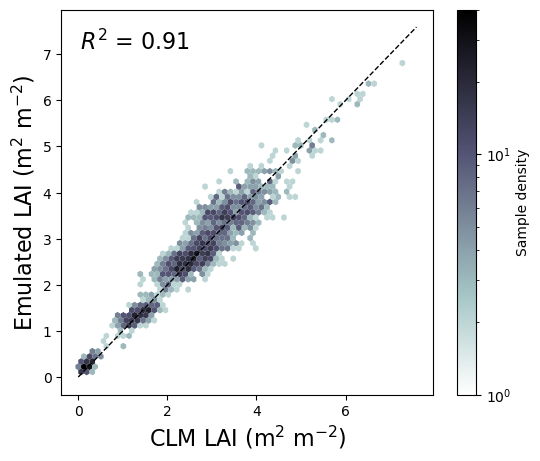

In [46]:

from matplotlib.colors import LogNorm



fig, ax = plt.subplots(figsize=(6, 5))

lims = [0, np.nanmax([lai_clm, lai_em])]

r2 = np.corrcoef(lai_clm, lai_em)[0, 1] ** 2

hb = ax.hexbin(
    lai_clm, lai_em,
    gridsize=60,
    extent=(lims[0], lims[1], lims[0], lims[1]),
    cmap="bone_r",
    norm=LogNorm(),      # or bins="log"

    mincnt=1,            # leave empty hexes unfilled
    linewidths=0,        # avoids hairline seams between hexes
)

ax.text(0.05, 0.95, rf"$R^2$ = {r2:.2f}",
        transform=ax.transAxes, ha="left", va="top",fontsize=16)

ax.plot(lims, lims, "k--", lw=1)
ax.set_xlabel(r"CLM LAI (m$^2$ m$^{-2}$)", fontsize=16)
ax.set_ylabel(r"Emulated LAI (m$^2$ m$^{-2}$)", fontsize=16)
plt.colorbar(hb, ax=ax, label="Sample density")
#plt.savefig('LAI_biome_emulator_hexbin.png',dpi=300)